# v2 — Notebook 02 · Preprocessing (EU monthly trade)

**Where we are:** EDA (notebook 01) is done. It handed us three decisions:
1. the data is **clean** → cleaning is minimal;
2. values grow ~exponentially → offer a **log transform**;
3. useful derived signals → **trade balance** (EXP − IMP) and **total trade** (EXP + IMP).

This notebook turns those decisions into reusable code. Following the **hybrid** design, the
logic lives in `v2/src/preprocess.py` and this notebook **imports and demonstrates** it — so the
same functions are used by later notebooks, the tests, and (later) the app.

> ⚠️ v2 = international trade, not v1's climate sensors.

## Step 0 · Setup — make `src` importable, locate the data

**What:** add the `v2/` folder to the import path (so `from src import preprocess` works) and
find the dataset. **Why:** a notebook can't be imported, but it *can* import a module — that's the
whole point of the hybrid layout.

In [1]:
import sys
from pathlib import Path

def find_v2_root():
    # walk up until we find the folder that contains 'src/preprocess.py'
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "src" / "preprocess.py").exists():
            return base
    raise FileNotFoundError("v2 root not found")

V2 = find_v2_root()
sys.path.insert(0, str(V2))                 # make `src` importable
DATA = V2.parent / "data" / "eu_trade_monthly.csv"

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
from src import preprocess as pp            # the module we're demonstrating
print("v2 root:", V2)
print("data   :", DATA, "(exists:", DATA.exists(), ")")

v2 root: /home/saizer/Documents/Msc_project/code/v2
data   : /home/saizer/Documents/Msc_project/code/data/eu_trade_monthly.csv (exists: True )


## Step 1 · Load & validate — *is it safe to build on?*

**What:** load the CSV and run the three quality checks (missing cells, calendar gaps,
non-positive flows). **Why:** these are the faults that silently corrupt rolling windows and
models. **How to read:** we want the report to say **CLEAN ✓**.

In [2]:
df = pp.load_trade(DATA)
report = pp.validate(df)
print(report)
print("\nis_clean:", report.is_clean)
print("countries:", len(pp.countries(df)), "| flow columns:", len(pp.flow_columns(df)))
df.iloc[:3, :6]

[CLEAN ✓] 292 months x 54 cols, 2002-01-01->2026-04-01 | missing cells=0, missing months=0, non-positive=0

is_clean: True
countries: 27 | flow columns: 54


,AT_EXP,AT_IMP,BE_EXP,BE_IMP,BG_EXP,BG_IMP
month,,,,,,
2002-01-01,6394.6,6412.6,18108.9,16616.2,427.9,563.5
2002-02-01,6545.2,6575.3,18065.6,16701.2,462.3,593.2
2002-03-01,7059.9,7235.7,20315.5,18545.3,466.8,622.7


## Step 2 · Derive features — *balance* and *total trade*

**What:** add two interpretable signals per country:
- **`CC_BAL` = exports − imports** → positive = surplus (sells more than it buys), negative = deficit.
- **`CC_TOT` = exports + imports** → overall trade activity.

**Why:** these answer real questions ("who runs a surplus?", "how big is this economy's trade?")
and become extra channels for analysis. **How to read:** France's balance sits **below zero**
(a persistent deficit); Belgium's sits **above zero** (a surplus).

columns now: 108 = 54 flows + 27 balance + 27 total


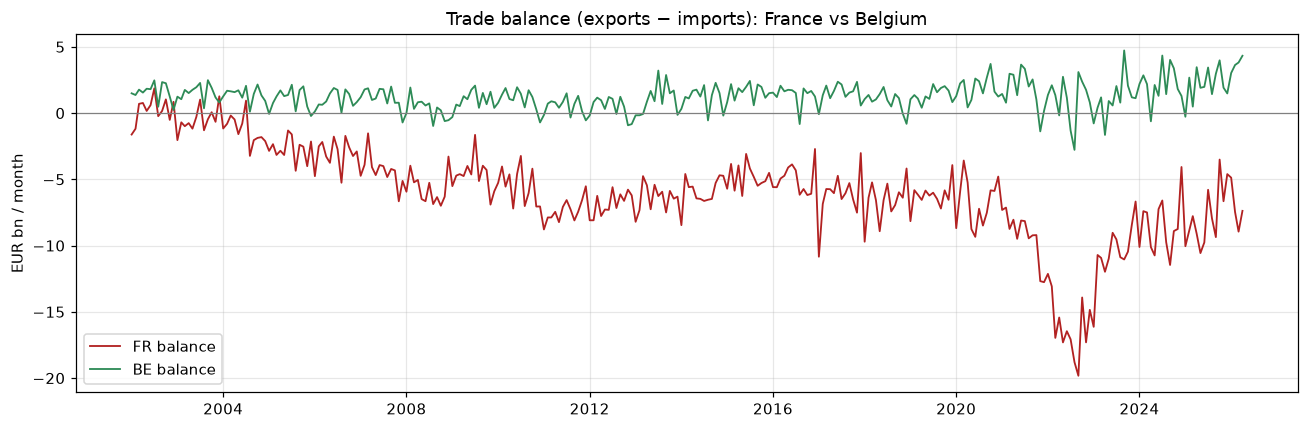

Latest balance (EUR bn):
FR_BAL   -7.4
BE_BAL    4.3


In [3]:
feat = pp.add_features(df)
print("columns now:", feat.shape[1], "= 54 flows + 27 balance + 27 total")

fig, ax = plt.subplots(figsize=(12, 4))
for cc, color in [("FR", "firebrick"), ("BE", "seagreen")]:
    ax.plot(feat.index, feat[f"{cc}_BAL"]/1000, label=f"{cc} balance", color=color, lw=1.2)
ax.axhline(0, color="grey", lw=.8)
ax.set_title("Trade balance (exports − imports): France vs Belgium")
ax.set_ylabel("EUR bn / month"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Latest balance (EUR bn):")
print((feat[["FR_BAL","BE_BAL"]].iloc[-1]/1000).round(1).to_string())

## Step 3 · Log transform — *make crises comparable across years*

**What:** replace each flow value with its natural log. **Why:** on the raw scale, a 30% drop in
2008 (≈ €25 bn) looks tiny next to 2026 levels (≈ €150 bn), so a detector tuned to recent data
*under-reacts* to old crises. On the **log scale**, a proportional change is the **same size in any
year**. **How to read:** left = raw (the early dips look small); right = log (2008 and COVID dips
are now visually comparable to later wobbles).

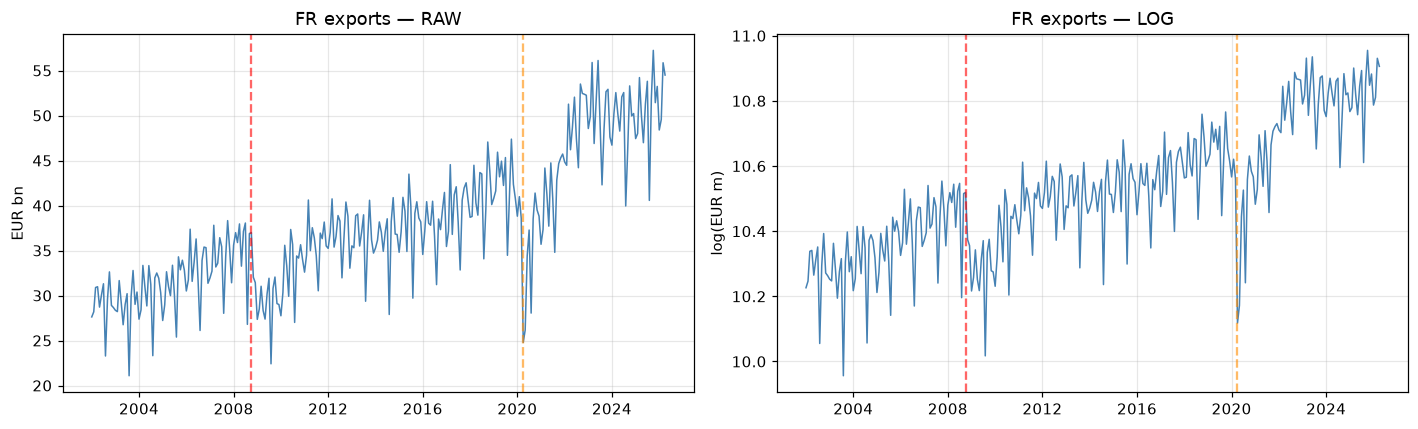

Std of monthly *changes* (a volatility proxy):
  raw  FR_EXP : 4,608 EUR m  (scale grows over time)
  log  FR_EXP : 0.131    (scale-free, comparable across years)


In [4]:
logged = pp.log_transform(df)               # logs only the flow columns
s_raw, s_log = df["FR_EXP"], logged["FR_EXP"]   # France exports as the example (not Germany)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, s, title, yl in [(ax[0], s_raw/1000, "FR exports — RAW", "EUR bn"),
                        (ax[1], s_log, "FR exports — LOG", "log(EUR m)")]:
    a.plot(s.index, s, color="steelblue", lw=1)
    for x, c in [("2008-10-01","red"), ("2020-04-01","darkorange")]:
        a.axvline(pd.Timestamp(x), color=c, ls="--", alpha=.6)
    a.set_title(title); a.set_ylabel(yl); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Numeric proof: month-to-month % moves become additive/comparable under log
print("Std of monthly *changes* (a volatility proxy):")
print(f"  raw  FR_EXP : {df['FR_EXP'].diff().std():,.0f} EUR m  (scale grows over time)")
print(f"  log  FR_EXP : {logged['FR_EXP'].diff().std():.3f}    (scale-free, comparable across years)")

## Step 4 · The one-call pipeline + save processed features

**What:** `pp.preprocess(path, log=?, features=?)` does load → (features) → (log) in one call.
We save the feature table (flows + balance + total) so later notebooks don't recompute it.
**Why:** one tested entry point keeps every downstream step consistent.

In [5]:
clean_feat = pp.preprocess(DATA, features=True)         # raw + balance + total
out = DATA.parent / "eu_trade_features.csv"
clean_feat.to_csv(out)
print("Saved:", out)
print("Shape:", clean_feat.shape, "(54 flows + 27 BAL + 27 TOT = 108 cols)")
print("\nSanity check vs the validator:", pp.validate(df).is_clean)
clean_feat.filter(regex="FR_").tail(3).round(0)

Saved: /home/saizer/Documents/Msc_project/code/data/eu_trade_features.csv
Shape: (292, 108) (54 flows + 27 BAL + 27 TOT = 108 cols)

Sanity check vs the validator: True


,FR_EXP,FR_IMP,FR_BAL,FR_TOT
month,,,,
2026-02-01,49549.0,57015.0,-7466.0,106564.0
2026-03-01,55861.0,64807.0,-8945.0,120668.0
2026-04-01,54494.0,61873.0,-7379.0,116368.0


## Step 5 · Summary

| EDA decision | Implemented as | Result |
| --- | --- | --- |
| Minimal cleaning | `validate()` | report says **CLEAN ✓** (0/0/0) |
| Derive signals | `trade_balance()`, `total_trade()`, `add_features()` | +54 columns (BAL, TOT) |
| Log transform | `log_transform()` | crises comparable across years; volatility scale-free |
| One entry point | `preprocess(path, log=?, features=?)` | used by notebooks, tests, app |

Output: `data/eu_trade_features.csv` (108 columns). Logic in `src/preprocess.py`,
covered by `tests/test_preprocess.py`.

**→ Next: Notebook 03 · Behaviour analysis** — trend slopes, STL (period = 12), rolling stats,
and country-to-country correlations, built on these preprocessed signals.